In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [2]:
wine_df = pd.read_csv(r'C:\Users\mrudu\OneDrive\Desktop\classification(ml)\Wine.csv')

In [3]:
wine_df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [6]:
wine_df.shape

(1599, 12)

In [7]:
wine_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [8]:
wine_df.columns

Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

In [9]:
wine_df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64


<Axes: xlabel='quality', ylabel='count'>

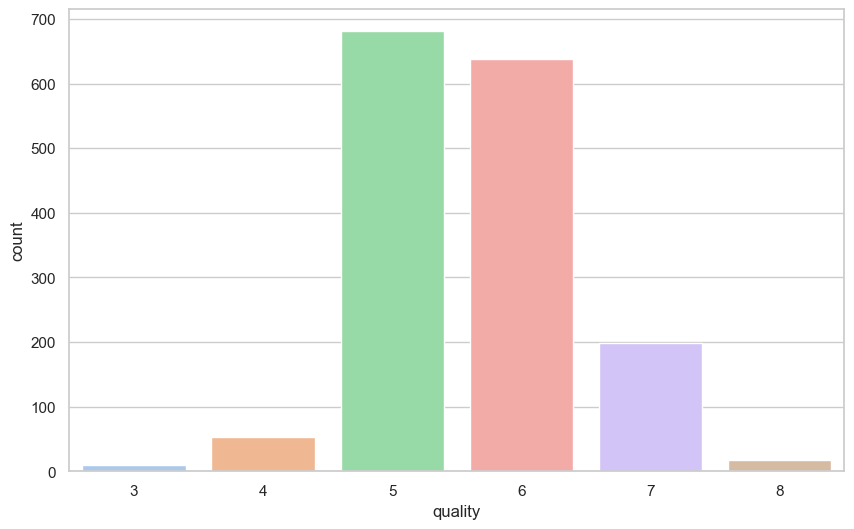

In [10]:
sns.set(style="whitegrid")
print(wine_df['quality'].value_counts())
fig = plt.figure(figsize = (10,6))
sns.countplot(x='quality', data=wine_df, palette='pastel')

<Axes: >

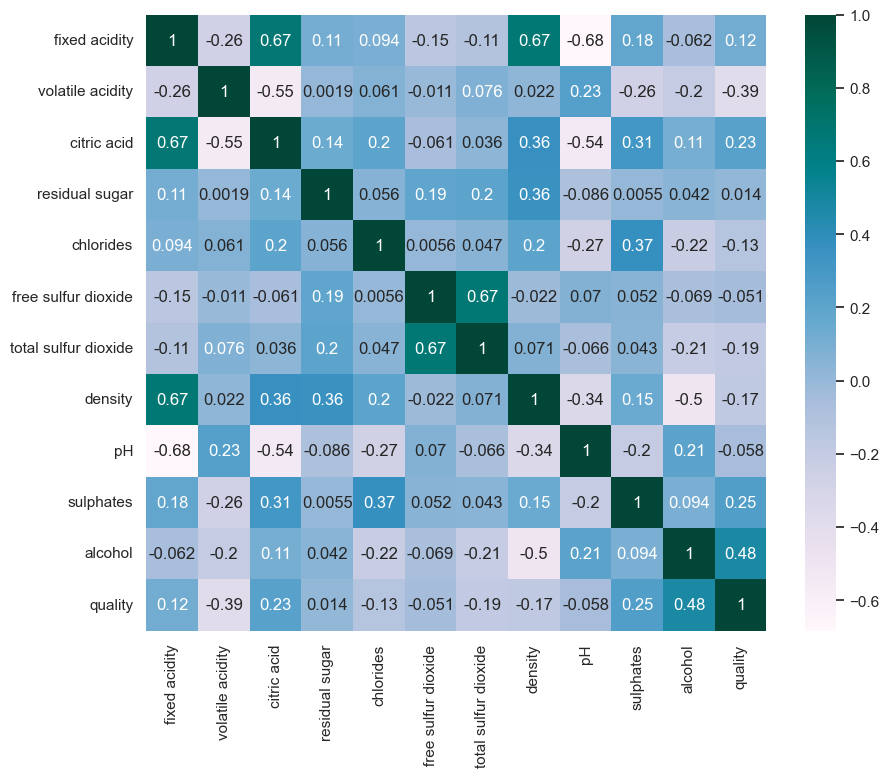

In [16]:
plt.figure(figsize = (10,8))
sns.heatmap(wine_df.corr(),annot=True, cmap= 'PuBuGn')

In [17]:
wine_df.corr()['quality'].sort_values(ascending=False)

quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64

In [18]:
x = wine_df.drop(columns=['quality'])
y = wine_df['quality']

In [19]:
y.value_counts()

quality
5    681
6    638
7    199
4     53
8     18
3     10
Name: count, dtype: int64

In [20]:
!pip install imbalanced-learn


   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   ---------------------------------------- 2/2 [imbalanced-learn]



In [22]:
from imblearn.over_sampling import SMOTE
oversample = SMOTE(k_neighbors=4)

x, y = oversample.fit_resample(x.fillna(0), y)

In [24]:
y.value_counts()

quality
5    681
6    681
7    681
4    681
8    681
3    681
Name: count, dtype: int64

In [23]:
# classify function
from sklearn.model_selection import  train_test_split

def classify(model, x, y):
    x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)
    # train the model
    model.fit(x_train, y_train)
    return model.score(x_test, y_test) * 100

In [25]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
LinearReg_acc=classify(model, x, y)
LinearReg_acc

48.043052837573384

In [28]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()
DecTree_acc=classify(model, x, y)
DecTree_acc

80.43052837573386

In [32]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier()
RanFor_acc=classify(model, x, y)
RanFor_acc

84.05088062622309

In [33]:
from sklearn.svm import SVC
model = SVC()
svm_acc = classify(model, x, y)
svm_acc

43.05283757338552

In [35]:
from sklearn.neighbors import KNeighborsClassifier
model = KNeighborsClassifier()
KNN_acc=classify(model, x, y)
KNN_acc


69.37377690802349

In [36]:
Accuracy = [LinearReg_acc, DecTree_acc,RanFor_acc,svm_acc, KNN_acc  ]
models = ['LogisticRegression', 'DecisionTreeClassifier', 'RandomForestClassifier', 'SVC', 'KNeighborsClassifier']

Text(0.5, 0, 'Accuracy on %')

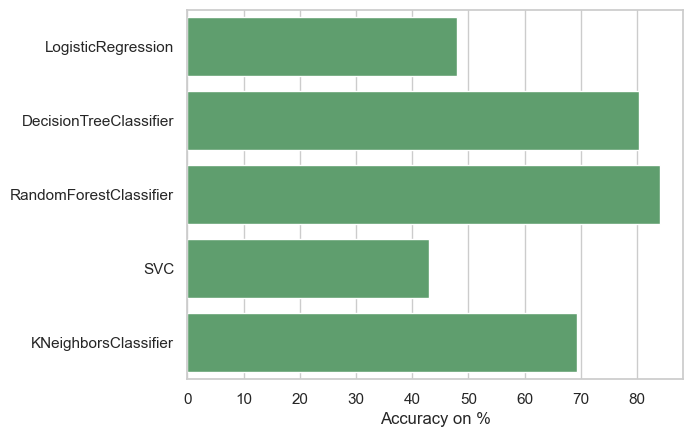

In [37]:
sns.barplot(x=Accuracy, y=models, color="g")
plt.xlabel('Accuracy on %')